# 02 — Modèles de recommandation

Trois approches comparées sur le découpage officiel **u1.base / u1.test** (80 000 / 20 000 notes) :

1. **Popularité / moyenne** : note = moyenne lissée du film ; top-N = films les plus notés.
2. **Item-KNN** : similarité cosinus ajustée entre films, 40 voisins.
3. **Factorisation matricielle** biaisée (type Funk SVD), entraînée par SGD.

Métriques : RMSE et MAE sur les notes, Precision@10 et Recall@10 (pertinent = note ≥ 4 dans le test, films vus à l'entraînement exclus).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import download, load_ratings, load_movies, GENRES
download()
VIOLET, GOLD = "#8B5CF6", "#F5C451"
from src.data import load_split
from src.models import PopularityBaseline, ItemKNN, MatrixFactorization
from src.metrics import rmse, mae, evaluate_top_n
train, test = load_split(1)
print(len(train), 'notes d\'entraînement ·', len(test), 'notes de test')

80000 notes d'entraînement · 20000 notes de test


In [2]:
models = {
    'Popularité / moyenne': PopularityBaseline(damping=5),
    'Item-KNN (cosinus)': ItemKNN(k=40, shrinkage=10),
    'Factorisation (SVD-SGD)': MatrixFactorization(n_factors=50, n_epochs=20, lr=0.01, reg=0.05, seed=42),
}
rows = []
for name, model in models.items():
    model.fit(train, valid=test) if isinstance(model, MatrixFactorization) else model.fit(train)
    pred = model.predict(test.user_id, test.item_id)
    top = evaluate_top_n(model, test, k=10)
    rows.append({'modèle': name, 'RMSE': rmse(test.rating, pred), 'MAE': mae(test.rating, pred),
                 'Precision@10': top['precision@10'], 'Recall@10': top['recall@10']})
results = pd.DataFrame(rows).set_index('modèle').round(4)
results

,RMSE,MAE,Precision@10,Recall@10
modèle,,,,
Popularité / moyenne,1.0370,0.8319,0.2129,0.1179
Item-KNN (cosinus),0.9963,0.7622,0.2947,0.1654
Factorisation (SVD-SGD),0.9339,0.7353,0.1333,0.0479


## Courbe d'apprentissage de la factorisation

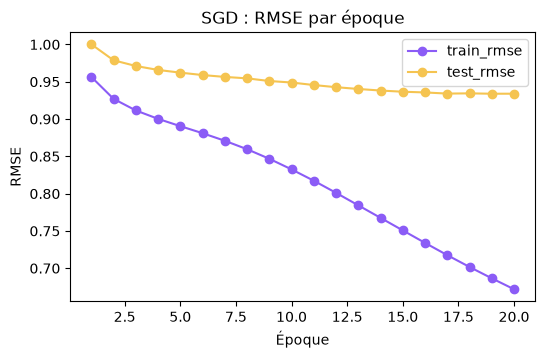

,epoch,train_rmse,test_rmse
17,18,0.7017,0.9344
18,19,0.6865,0.9339
19,20,0.6719,0.9339


In [3]:
hist = pd.DataFrame(models['Factorisation (SVD-SGD)'].history_)
ax = hist.plot(x='epoch', y=['train_rmse', 'test_rmse'], marker='o', color=[VIOLET, GOLD], figsize=(6, 3.5))
ax.set_xlabel('Époque'); ax.set_ylabel('RMSE'); ax.set_title('SGD : RMSE par époque')
plt.show()
hist.tail(3).round(4)

## Exemple : recommandations pour l'utilisateur 1

In [4]:
movies = load_movies().set_index('item_id').title
vus = train[train.user_id == 1].sort_values('rating', ascending=False).head(5)
print('Quelques films qu\'il a adorés :')
print(vus.item_id.map(movies).to_string(index=False))
pd.DataFrame({name: [movies[i] for i in m.recommend(1, 10)] for name, m in models.items()}, index=range(1, 11))

Quelques films qu'il a adorés :
                  Toy Story (1995)
                      Crumb (1994)
             Antonia's Line (1995)
French Twist (Gazon maudit) (1995)
         Mr. Holland's Opus (1995)


,Popularité / moyenne,Item-KNN (cosinus),Factorisation (SVD-SGD)
1,Contact (1997),Raiders of the Lost Ark (1981),Secrets & Lies (1996)
2,Fargo (1996),"Usual Suspects, The (1995)",Fargo (1996)
3,Liar Liar (1997),Terminator 2: Judgment Day (1991),Citizen Kane (1941)
4,Scream (1996),Alien (1979),M (1931)
5,"English Patient, The (1996)","Silence of the Lambs, The (1991)",Lawrence of Arabia (1962)
6,Independence Day (ID4) (1996),Indiana Jones and the Last Crusade (1989),"Close Shave, A (1995)"
7,Air Force One (1997),"Shawshank Redemption, The (1994)",Three Colors: Blue (1993)
8,Raiders of the Lost Ark (1981),Schindler's List (1993),Vertigo (1958)
9,Pulp Fiction (1994),"Hunt for Red October, The (1990)",Wallace & Gromit: The Best of Aardman Animatio...
10,"Rock, The (1996)",Star Trek: The Wrath of Khan (1982),Raiders of the Lost Ark (1981)


## Lecture des résultats

- La **factorisation** prédit le mieux les notes (RMSE la plus basse).
- **Item-KNN** fournit le meilleur top-10 : prédire une note précise et classer les films sont deux problèmes différents.
- Classer par note prédite favorise des films peu vus avec une forte moyenne estimée, d'où une Precision@10 plus faible pour la factorisation ; la **popularité** reste une référence solide.
- Pistes : optimiser directement le classement (BPR, ALS implicite), validation croisée sur les 5 découpages, hyperparamètres.